In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import scipy.stats as stats

In [2]:
# Set the random seed for reproducibility
np.random.seed(42)

# Create a synthetic dataset
data = {
    'product_id': range(1, 21),
    'product_name': [f'Product {i}' for i in range(1, 21)],
    'category': np.random.choice(['Electronics', 'Clothing', 'Home', 'Sports'], 20),
    'units_sold': np.random.poisson(lam=20, size=20),  # Poisson distribution for sales
    'sale_date': pd.date_range(start='2023-01-01', periods=20, freq='D')
}

sales_data = pd.DataFrame(data)

# Display the first few rows of the dataset
print("Sales Data:")
print(sales_data)

Sales Data:
    product_id product_name     category  units_sold  sale_date
0            1    Product 1         Home          25 2023-01-01
1            2    Product 2       Sports          15 2023-01-02
2            3    Product 3  Electronics          17 2023-01-03
3            4    Product 4         Home          19 2023-01-04
4            5    Product 5         Home          21 2023-01-05
5            6    Product 6       Sports          17 2023-01-06
6            7    Product 7  Electronics          19 2023-01-07
7            8    Product 8  Electronics          16 2023-01-08
8            9    Product 9         Home          21 2023-01-09
9           10   Product 10     Clothing          21 2023-01-10
10          11   Product 11         Home          17 2023-01-11
11          12   Product 12         Home          22 2023-01-12
12          13   Product 13         Home          14 2023-01-13
13          14   Product 14         Home          17 2023-01-14
14          15   Product 15 

In [3]:
# Save the DataFrame as a CSV file
sales_data.to_csv('sales_data.csv', index=False)

In [4]:
#path location
import os
os.getcwd()

'd:\\ABHI-VSCODE\\STATISTICS-WORKSHOP'

# 3. Descriptive statistics

In [5]:
# Descriptive statistics
descriptive_stats = sales_data['units_sold'].describe()

# Display descriptive statistics
print("\nDescriptive Statistics for Units Sold:")
print(descriptive_stats)

# Additional statistics
mean_sales = sales_data['units_sold'].mean()
median_sales = sales_data['units_sold'].median()
mode_sales = sales_data['units_sold'].mode()[0]
variance_sales = sales_data['units_sold'].var()
std_deviation_sales = sales_data['units_sold'].std()

# Group by category and calculate total and average sales
category_stats = sales_data.groupby('category')['units_sold'].agg(['sum', 'mean', 'std']).reset_index()


# Display the results

print("\nStatistical Analysis:")
print(f"Mean Units Sold: {mean_sales}")
print(f"Median Units Sold: {median_sales}")
print(f"Mode Units Sold: {mode_sales}")
print(f"Variance of Units Sold: {variance_sales}")
print(f"Standard Deviation of Units Sold: {std_deviation_sales}")
print("\nCategory Statistics:")
print(category_stats)


Descriptive Statistics for Units Sold:
count    20.000000
mean     18.800000
std       3.302312
min      13.000000
25%      17.000000
50%      18.500000
75%      21.000000
max      25.000000
Name: units_sold, dtype: float64

Statistical Analysis:
Mean Units Sold: 18.8
Median Units Sold: 18.5
Mode Units Sold: 17
Variance of Units Sold: 10.905263157894737
Standard Deviation of Units Sold: 3.302311789927586

Category Statistics:
      category  sum       mean       std
0     Clothing   21  21.000000       NaN
1  Electronics   73  18.250000  2.217356
2         Home  181  20.111111  3.723051
3       Sports  101  16.833333  2.714160


# 4.inferential statstics

In [12]:
#inferential statstics

# Confidence Interval for the mean of units sold
confidence_level = 0.99
degrees_freedom = len(sales_data['units_sold']) - 1
sample_mean = mean_sales
sample_standard_error = std_deviation_sales / np.sqrt(len(sales_data['units_sold']))



# t-score for the confidence level

t_score = stats.t.ppf((1 + confidence_level) / 2, degrees_freedom)
margin_of_error = t_score * sample_standard_error


confidence_interval = (sample_mean - margin_of_error, sample_mean + margin_of_error)
print("\nConfidence Interval for the Mean of Units Sold:")
print(confidence_interval)


Confidence Interval for the Mean of Units Sold:
(np.float64(16.68743048596741), np.float64(20.91256951403259))


# 5.Hypothesis Testing

In [7]:
t_statistics, p_value = stats.ttest_1samp(sales_data['units_sold'], 20)

print('\n Hypothesis Testing (t-test):')
print(f"t-statistic: {t_statistics}")
print(f"p-value: {p_value}")

if p_value < 0.05:
    print("Reject the null hypothesis: The mean units sold is significantly different from 20.")
else:
    print("Fail to reject the null hypothesis: The mean units sold is not significantly different from 20.")


 Hypothesis Testing (t-test):
t-statistic: -1.6250928099424466
p-value: 0.12061572226781007
Fail to reject the null hypothesis: The mean units sold is not significantly different from 20.


# 6. visualization

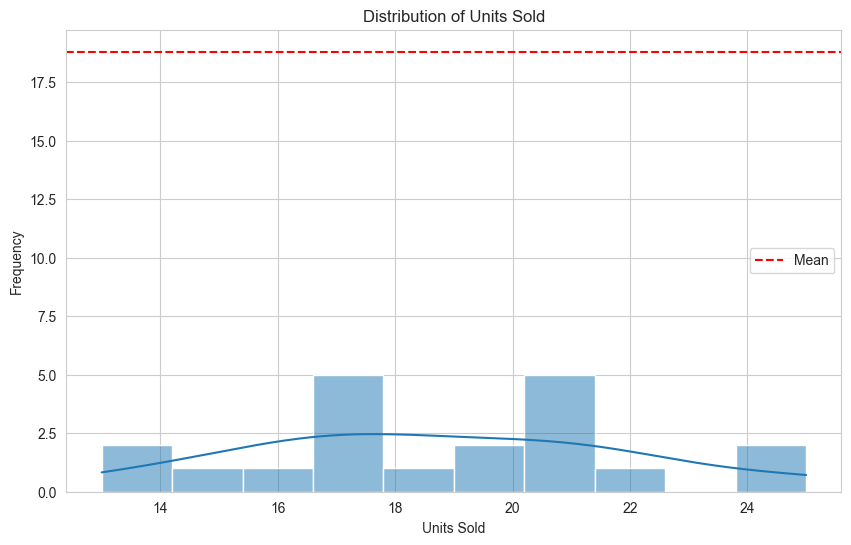

In [8]:
# visualization

sns.set_style('whitegrid')

#plt distribution
plt.figure(figsize=(10, 6))
sns.histplot(sales_data['units_sold'], bins=10, kde=True)
plt.title('Distribution of Units Sold')
plt.xlabel('Units Sold')
plt.ylabel('Frequency')
plt.axhline(sample_mean, color='red', linestyle='--', label='Mean')
plt.legend()
plt.show()

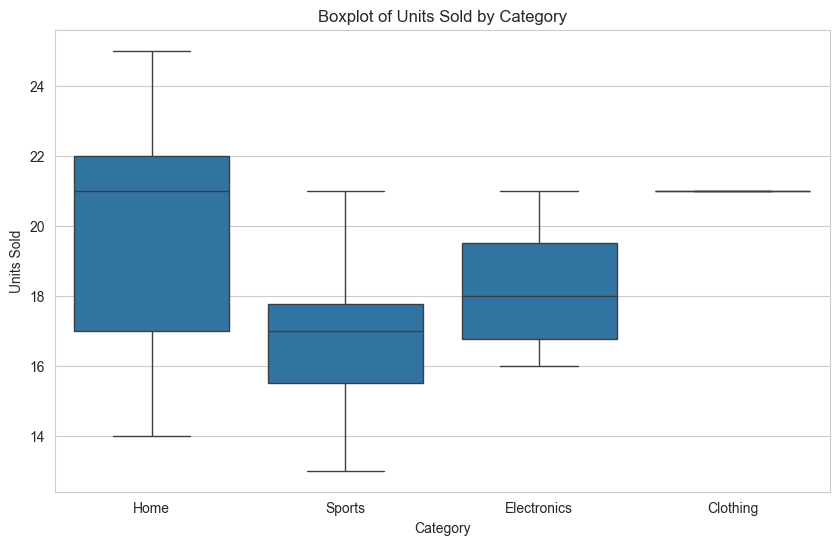

In [9]:
#Boxplot for unit sold by category
plt.figure(figsize=(10, 6))
sns.boxplot(x='category', y='units_sold', data=sales_data)
plt.title('Boxplot of Units Sold by Category')
plt.xlabel('Category')
plt.ylabel('Units Sold')
plt.show()

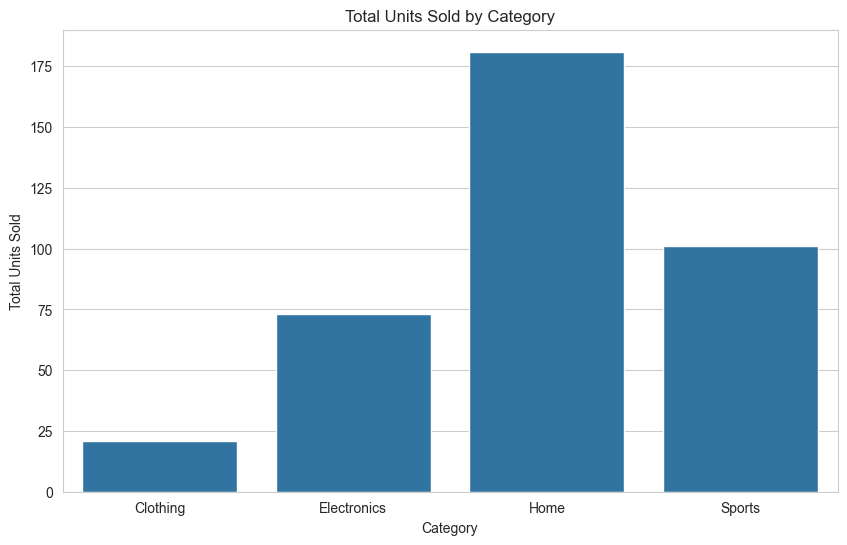

In [11]:
#Barplot for unit sold by category
plt.figure(figsize=(10, 6))
sns.barplot(x='category', y='sum', data=category_stats)
plt.title('Total Units Sold by Category')
plt.xlabel('Category')
plt.ylabel('Total Units Sold')
plt.show()